# 04. Experiment C: embedding model

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

MiniLM (22M params) vs. bge-small (33M, the default) vs. Qwen3-Embedding-0.6B
(1024-dim, the quality ceiling), holding chunking (section) and mode (hybrid)
fixed. The scatter plots accuracy against p50 query latency to show the
accuracy/latency trade-off directly.


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import pandas as pd

W1030 15:30:35.171000 51416 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [2]:
model_results = {}
for model_name in ["minilm", "bge-small", "qwen3-0.6b"]:
    model_results[model_name] = s.run_eval(
        model=model_name, chunking="section", mode="hybrid", warm_runs=5
    )

model_df = pd.DataFrame(
    {
        m: {
            **res["retrieval_accuracy"]["macro_avg"],
            "p50_total_ms": res["latency"]["query"]["macro_avg"]["total"]["p50_ms"],
            "model_cold_load_s": res["latency"]["model_cold_load_s"],
        }
        for m, res in model_results.items()
    }
).T
model_df

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1,p50_total_ms,model_cold_load_s
minilm,0.900000,0.716667,0.652778,1.0,0.886695,1.0,40.598250,1.799
bge-small,0.900000,0.716667,0.652778,1.0,0.884672,1.0,43.946223,1.916
qwen3-0.6b,0.933333,0.766667,0.694444,1.0,0.903777,1.0,240.623292,7.645


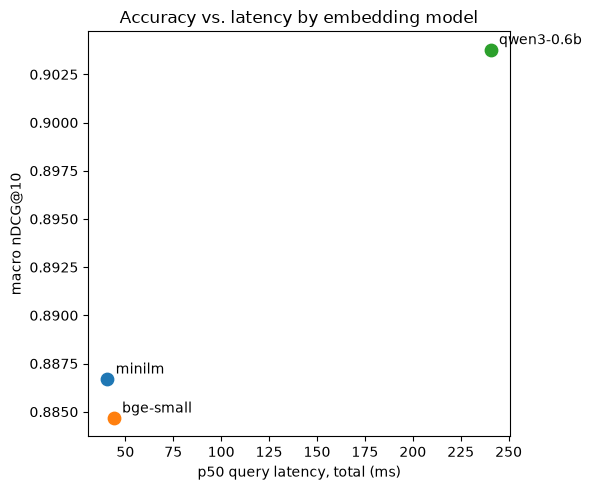

In [3]:
plt.figure(figsize=(6, 5))
for model_name, row in model_df.iterrows():
    plt.scatter(row["p50_total_ms"], row["ndcg_at_10"], s=80)
    plt.annotate(
        model_name,
        (row["p50_total_ms"], row["ndcg_at_10"]),
        xytext=(6, 4),
        textcoords="offset points",
    )
plt.xlabel("p50 query latency, total (ms)")
plt.ylabel("macro nDCG@10")
plt.title("Accuracy vs. latency by embedding model")
plt.tight_layout()
plt.show()

In [4]:
for name, row in model_df.iterrows():
    print(f"{name:<10} nDCG@10={row['ndcg_at_10']:.3f}  p50={row['p50_total_ms']:.1f}ms")

minilm     nDCG@10=0.887  p50=40.6ms
bge-small  nDCG@10=0.885  p50=43.9ms
qwen3-0.6b nDCG@10=0.904  p50=240.6ms


**Finding:** `qwen3-0.6b` buys some accuracy over `bge-small` at several
times the query latency (and a much heavier cold load). At this dataset's
scale, `bge-small` is the better default; `qwen3-0.6b` is worth it only if
the accuracy gap matters more than latency for a given deployment.
